# CICIoT2023 — EDA Restart

Check that each dataset split exists, then count its rows in chunks and read its header to summarize its dimensions.

In [1]:
from pathlib import Path
import pandas as pd

from dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}

missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing dataset files:\n" + "\n".join(missing))

summary = []
for split, path in files.items():
    columns = len(pd.read_csv(path, nrows=0).columns)
    rows = sum(len(chunk) for chunk in pd.read_csv(path, chunksize=100_000))
    summary.append({
        "Split": split,
        "File size (MiB)": round(path.stat().st_size / 1024**2, 2),
        "Total rows": rows,
        "Columns": columns,
    })

summary_df = pd.DataFrame(summary)
display(summary_df.set_index("Split"))
print(f"Combined total rows: {summary_df['Total rows'].sum():,}")

,File size (MiB),Total rows,Columns
Split,,,
Train,1548.24,5491971,47
Validation,331.80,1176851,47
Test,331.84,1176851,47


Combined total rows: 7,845,673


Compare the column names and order across the three splits, then inspect the training columns and first five records. These are the first records, not a representative random sample.

In [1]:
from pathlib import Path
import pandas as pd

from dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
headers = {split: pd.read_csv(path, nrows=0).columns.tolist() for split, path in files.items()}
match = headers["Train"] == headers["Validation"] == headers["Test"]
print(f"Column names and order match exactly across all splits: {match}")

columns = pd.DataFrame({"Column name": headers["Train"]})
columns.index = pd.RangeIndex(1, len(columns) + 1, name="Number")
display(columns)

first_records = pd.read_csv(files["Train"], nrows=5)
display(first_records.T)

Column names and order match exactly across all splits: True


,Column name
Number,
1,flow_duration
2,Header_Length
3,Protocol Type
4,Duration
5,Rate
6,Srate
7,Drate
8,fin_flag_number
9,syn_flag_number


,0,1,2,3,4
flow_duration,0.0,0.0,0.033982,0.0,3.944828
Header_Length,757.0,54.0,56.78,0.0,108.0
Protocol Type,6.0,6.0,6.11,47.0,6.0
Duration,64.0,64.0,64.64,64.0,64.0
Rate,23.671858,2.393046,1.192715,9.841972,0.506993
Srate,23.671858,2.393046,1.192715,9.841972,0.506993
Drate,0.0,0.0,0.0,0.0,0.0
fin_flag_number,0.0,0.0,0.0,0.0,0.0
syn_flag_number,0.0,1.0,0.0,0.0,1.0
rst_flag_number,0.0,0.0,0.0,0.0,0.0


We are checking original traffic-label frequencies before choosing stratified random subsets, so rare labels are not accidentally overlooked.

In [ ]:
from pathlib import Path
import pandas as pd

from dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
row_totals = summary_df.set_index("Split")["Total rows"]
counts = {}
missing_counts = {}
for split, path in files.items():
    split_counts = pd.Series(dtype="int64")
    missing_count = 0
    for chunk in pd.read_csv(path, usecols=["label"], chunksize=100_000):
        labels = chunk["label"]
        split_counts = split_counts.add(labels.value_counts(), fill_value=0)
        missing_count += labels.isna().sum()
    counts[split] = split_counts.astype("int64")
    missing_counts[split] = missing_count
    assert int(split_counts.sum()) + missing_count == row_totals[split], f"Label total mismatch for {split}"

label_table = pd.DataFrame(index=sorted(set().union(*(counts[s].index for s in files))))
label_table.index.name = "Label"
for split in files:
    label_table[f"{split} count"] = counts[split].reindex(label_table.index, fill_value=0)
    label_table[f"{split} %"] = (label_table[f"{split} count"] / row_totals[split] * 100).round(4)
display(label_table)
print("Missing labels: " + ", ".join(f"{split}: {count:,}" for split, count in missing_counts.items()))
print("Label counts plus missing labels match the previously calculated row totals for all splits.")

,Train count,Train %,Validation count,Validation %,Test count,Test %
Label,,,,,,
Backdoor_Malware,392,0.0071,93,0.0079,89,0.0076
BenignTraffic,129538,2.3587,27519,2.3384,27709,2.3545
BrowserHijacking,665,0.0121,158,0.0134,134,0.0114
CommandInjection,620,0.0113,132,0.0112,119,0.0101
DDoS-ACK_Fragmentation,33581,0.6115,7194,0.6113,7292,0.6196
DDoS-HTTP_Flood,3371,0.0614,706,0.0600,709,0.0602
DDoS-ICMP_Flood,848088,15.4423,182011,15.4659,180447,15.3330
DDoS-ICMP_Fragmentation,53046,0.9659,11430,0.9712,11402,0.9689
DDoS-PSHACK_Flood,481254,8.7629,102985,8.7509,103326,8.7799


Missing labels: Train: 0, Validation: 0, Test: 0
Label counts plus missing labels match the previously calculated row totals for all splits.


## Stratified random subsets and class proportions

Within each existing split, we sample whole records separately for each original label. Stratification approximately preserves label proportions. It does not balance the classes or resolve overlap between splits. Class imbalance describes unequal label frequencies. Numerical feature skewness describes asymmetry in the distribution of a numerical feature.

In [3]:
from pathlib import Path
import pandas as pd

from dataset_paths import dataset_root

dataset_dir = dataset_root()
files = {
    "Train": dataset_dir / "CICIOT23/train/train.csv",
    "Validation": dataset_dir / "CICIOT23/validation/validation.csv",
    "Test": dataset_dir / "CICIOT23/test/test.csv",
}
from collections import Counter

import numpy as np

subset_sizes = {"Train": 100_000, "Validation": 25_000, "Test": 25_000}
chunk_size = 50_000
# Preserve literal CSV field values and treat empty labels as missing.
csv_options = {"keep_default_na": False, "skip_blank_lines": False}

# Saved counts from the preceding label inspection, checked against its row totals
# and recorded file sizes. For changed files, read only the label column in chunks.
saved_labels = ['Backdoor_Malware', 'BenignTraffic', 'BrowserHijacking', 'CommandInjection', 'DDoS-ACK_Fragmentation', 'DDoS-HTTP_Flood', 'DDoS-ICMP_Flood', 'DDoS-ICMP_Fragmentation', 'DDoS-PSHACK_Flood', 'DDoS-RSTFINFlood', 'DDoS-SYN_Flood', 'DDoS-SlowLoris', 'DDoS-SynonymousIP_Flood', 'DDoS-TCP_Flood', 'DDoS-UDP_Flood', 'DDoS-UDP_Fragmentation', 'DNS_Spoofing', 'DictionaryBruteForce', 'DoS-HTTP_Flood', 'DoS-SYN_Flood', 'DoS-TCP_Flood', 'DoS-UDP_Flood', 'MITM-ArpSpoofing', 'Mirai-greeth_flood', 'Mirai-greip_flood', 'Mirai-udpplain', 'Recon-HostDiscovery', 'Recon-OSScan', 'Recon-PingSweep', 'Recon-PortScan', 'SqlInjection', 'Uploading_Attack', 'VulnerabilityScan', 'XSS']
saved_counts = {
    'Train': [392, 129538, 665, 620, 33581, 3371, 848088, 53046, 481254, 475441, 478653, 2757, 422083, 528499, 637558, 34169, 21214, 1541, 8487, 237573, 314174, 390422, 36316, 116133, 88821, 104814, 15737, 11587, 249, 9648, 590, 140, 4396, 414],
    'Validation': [93, 27519, 158, 132, 7194, 706, 182011, 11430, 102985, 101563, 102644, 620, 90795, 113888, 136466, 7221, 4565, 290, 1833, 51115, 67056, 83446, 7741, 24910, 18867, 22314, 3482, 2500, 45, 2083, 148, 35, 905, 91],
    'Test': [89, 27709, 134, 119, 7292, 709, 180447, 11402, 103326, 101819, 102208, 622, 90480, 113735, 136717, 7224, 4570, 319, 1805, 51116, 67697, 83627, 7840, 24934, 19279, 22536, 3331, 2433, 53, 2082, 148, 33, 913, 103],
}
saved_missing = {'Train': 0, 'Validation': 0, 'Test': 0}
saved_file_stats = {'Train': (1623446296, 1794863541742735483), 'Validation': (347921865, 1794863543910373465), 'Test': (347958926, 1794863532455238655)}

full_counts = {}
missing_labels = {}
for split, source in files.items():
    stat = source.stat()
    if (stat.st_size, stat.st_mtime_ns) == saved_file_stats[split]:
        full_counts[split] = Counter(dict(zip(saved_labels, saved_counts[split], strict=True)))
        missing_labels[split] = saved_missing[split]
        continue
    counts = Counter()
    for chunk in pd.read_csv(
        source, usecols=["label"], dtype=str, chunksize=chunk_size, **csv_options
    ):
        counts.update(chunk["label"].fillna("").value_counts().to_dict())
    missing_labels[split] = counts.pop("", 0)
    full_counts[split] = counts

print("Missing labels — " + ", ".join(
    f"{split}: {count:,}" for split, count in missing_labels.items()
))
if any(missing_labels.values()):
    raise ValueError("Review missing labels before sampling.")

allocations = {}
for split, requested in subset_sizes.items():
    counts = full_counts[split]
    total = counts.total()
    if not 0 < requested <= total:
        raise ValueError(f"{split}: requested {requested:,} records from {total:,} available.")
    # Give leftover places to the largest fractional remainders. Break ties by label.
    quotas = {label: divmod(count * requested, total) for label, count in counts.items() if count}
    allocated = {label: whole for label, (whole, _) in quotas.items()}
    remaining = requested - sum(allocated.values())
    for label in sorted(quotas, key=lambda label: (-quotas[label][1], label))[:remaining]:
        allocated[label] += 1
    allocations[split] = allocated

sparse = [
    {"Split": split, "Label": label, "Allocated": count}
    for split, allocated in allocations.items()
    for label, count in sorted(allocated.items())
    if count < 20
]
if sparse:
    print("Sparse allocations (fewer than 20 records)")
    display(pd.DataFrame(sparse).set_index(["Split", "Label"]))
if any(row["Allocated"] == 0 for row in sparse):
    zero_labels = [f'{row["Split"]} / {row["Label"]}' for row in sparse if row["Allocated"] == 0]
    raise ValueError("Review subset sizes before sampling. Zero allocations: " + ", ".join(zero_labels))


Missing labels — Train: 0, Validation: 0, Test: 0
Sparse allocations (fewer than 20 records)


Allocated
Split      Label                          
Train      Backdoor_Malware              7
           BrowserHijacking             12
           CommandInjection             11
           Recon-PingSweep               5
           SqlInjection                 11
           Uploading_Attack              3
           XSS                           8
Validation Backdoor_Malware              2
           BrowserHijacking              3
           CommandInjection              3
           DDoS-HTTP_Flood              15
           DDoS-SlowLoris               13
           DictionaryBruteForce          6
           Recon-PingSweep               1
           SqlInjection                  3
           Uploading_Attack              1
           VulnerabilityScan            19
           XSS                           2
Test       Backdoor_Malware              2
           BrowserHijacking              3
           CommandInjection              3
           DDoS-HTTP_Flood              15
           DDoS-SlowLoris               13
           DictionaryBruteForce          7
           Recon-PingSweep               1
           SqlInjection                  3
           Uploading_Attack              1
           VulnerabilityScan            19
           XSS                           2

In [4]:
from tempfile import TemporaryDirectory

subset_dir = Path("data/subsets")
subset_paths = {
    split: subset_dir / f"ciciot2023_{split.lower()}_stratified_{size}_seed42.csv"
    for split, size in subset_sizes.items()
}
existing = [path for path in subset_paths.values() if path.exists() or path.is_symlink()]
if existing:
    raise FileExistsError("Subset files already exist:\n" + "\n".join(map(str, existing)))

rng = np.random.default_rng(42)
subset_dir.mkdir(parents=True, exist_ok=True)
with TemporaryDirectory(dir=subset_dir) as staging:
    for split, source in files.items():
        # Draw positions in each label's full-file sequence, then resolve them in one pass.
        positions = {
            label: np.sort(rng.choice(full_counts[split][label], size, replace=False))
            for label, size in sorted(allocations[split].items())
        }
        seen = Counter()
        selected = Counter()
        staged_path = Path(staging) / subset_paths[split].name
        with staged_path.open("w", encoding="utf-8", newline="") as output:
            for chunk_number, chunk in enumerate(pd.read_csv(
                source, dtype=str, chunksize=chunk_size, **csv_options
            )):
                if chunk_number == 0:
                    chunk.head(0).to_csv(output, index=False)
                keep = np.zeros(len(chunk), dtype=bool)
                for label, indices in chunk.groupby("label", sort=False, dropna=False).indices.items():
                    if label not in positions:
                        raise ValueError(f"{split}: unexpected label {label!r}.")
                    start = seen[label]
                    seen[label] += len(indices)
                    ranks = positions[label]
                    left, right = ranks.searchsorted([start, seen[label]])
                    keep[indices[ranks[left:right] - start]] = True
                    selected[label] += right - left
                chunk.loc[keep].to_csv(output, index=False, header=False)
        if seen != full_counts[split] or selected != Counter(allocations[split]):
            raise ValueError(f"{split}: label counts changed or the sample is incomplete.")

    published = []
    try:
        for destination in subset_paths.values():
            # Linking publishes a complete file and fails if the destination exists.
            destination.hardlink_to(Path(staging) / destination.name)
            published.append(destination)
    except OSError:
        for destination in published:
            destination.unlink()
        raise


,Saved path,Rows
Split,,
Train,data/subsets/ciciot2023_train_stratified_100000_seed42.csv,100000
Validation,data/subsets/ciciot2023_validation_stratified_25000_seed42.csv,25000
Test,data/subsets/ciciot2023_test_stratified_25000_seed42.csv,25000


Train                       Validation               \
                         Full % Subset count Subset %     Full % Subset count   
Label                                                                           
Backdoor_Malware         0.0071            7   0.0070     0.0079            2   
BenignTraffic            2.3587         2359   2.3590     2.3384          585   
BrowserHijacking         0.0121           12   0.0120     0.0134            3   
CommandInjection         0.0113           11   0.0110     0.0112            3   
DDoS-ACK_Fragmentation   0.6115          611   0.6110     0.6113          153   
DDoS-HTTP_Flood          0.0614           61   0.0610     0.0600           15   
DDoS-ICMP_Flood         15.4423        15442  15.4420    15.4659         3867   
DDoS-ICMP_Fragmentation  0.9659          966   0.9660     0.9712          243   
DDoS-PSHACK_Flood        8.7629         8763   8.7630     8.7509         2188   
DDoS-RSTFINFlood         8.6570         8657   8.6570     8.6301         2158   
DDoS-SYN_Flood           8.7155         8715   8.7150     8.7219         2180   
DDoS-SlowLoris           0.0502           50   0.0500     0.0527           13   
DDoS-SynonymousIP_Flood  7.6855         7685   7.6850     7.7151         1929   
DDoS-TCP_Flood           9.6231         9623   9.6230     9.6774         2419   
DDoS-UDP_Flood          11.6089        11609  11.6090    11.5959         2899   
DDoS-UDP_Fragmentation   0.6222          622   0.6220     0.6136          153   
DNS_Spoofing             0.3863          386   0.3860     0.3879           97   
DictionaryBruteForce     0.0281           28   0.0280     0.0246            6   
DoS-HTTP_Flood           0.1545          155   0.1550     0.1558           39   
DoS-SYN_Flood            4.3258         4326   4.3260     4.3434         1086   
DoS-TCP_Flood            5.7206         5721   5.7210     5.6979         1424   
DoS-UDP_Flood            7.1090         7109   7.1090     7.0906         1773   
MITM-ArpSpoofing         0.6613          661   0.6610     0.6578          164   
Mirai-greeth_flood       2.1146         2115   2.1150     2.1167          529   
Mirai-greip_flood        1.6173         1617   1.6170     1.6032          401   
Mirai-udpplain           1.9085         1908   1.9080     1.8961          474   
Recon-HostDiscovery      0.2865          287   0.2870     0.2959           74   
Recon-OSScan             0.2110          211   0.2110     0.2124           53   
Recon-PingSweep          0.0045            5   0.0050     0.0038            1   
Recon-PortScan           0.1757          176   0.1760     0.1770           44   
SqlInjection             0.0107           11   0.0110     0.0126            3   
Uploading_Attack         0.0025            3   0.0030     0.0030            1   
VulnerabilityScan        0.0800           80   0.0800     0.0769           19   
XSS                      0.0075            8   0.0080     0.0077            2   

                                    Test                        
                        Subset %  Full % Subset count Subset %  
Label                                                           
Backdoor_Malware          0.0080  0.0076            2   0.0080  
BenignTraffic             2.3400  2.3545          589   2.3560  
BrowserHijacking          0.0120  0.0114            3   0.0120  
CommandInjection          0.0120  0.0101            3   0.0120  
DDoS-ACK_Fragmentation    0.6120  0.6196          155   0.6200  
DDoS-HTTP_Flood           0.0600  0.0602           15   0.0600  
DDoS-ICMP_Flood          15.4680 15.3330         3833  15.3320  
DDoS-ICMP_Fragmentation   0.9720  0.9689          242   0.9680  
DDoS-PSHACK_Flood         8.7520  8.7799         2195   8.7800  
DDoS-RSTFINFlood          8.6320  8.6518         2163   8.6520  
DDoS-SYN_Flood            8.7200  8.6849         2171   8.6840  
DDoS-SlowLoris            0.0520  0.0529           13   0.0520  
DDoS-SynonymousIP_Flood   7.7160  7.6883         1922

,Largest absolute difference (pp)
Split,
Train,0.0005
Validation,0.0021
Test,0.0020


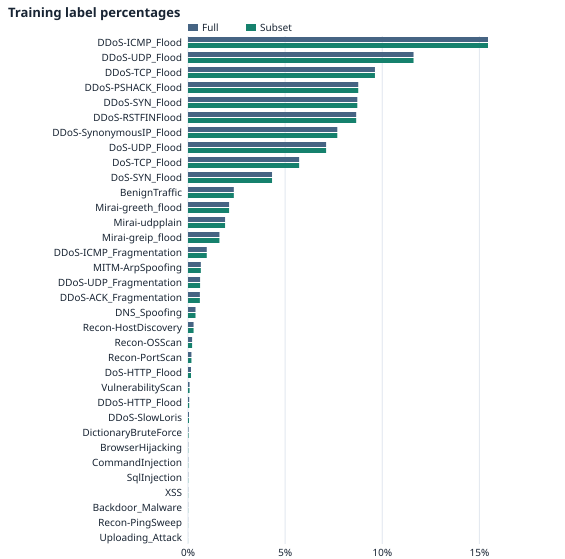

In [5]:
from html import escape

from IPython.display import SVG, display

saved_rows = {}
comparison = {}
max_differences = {}
labels = sorted(set().union(*(counts.keys() for counts in full_counts.values())))
for split, path in subset_paths.items():
    subset_counts = Counter()
    for chunk in pd.read_csv(path, usecols=["label"], dtype=str, chunksize=chunk_size, **csv_options):
        subset_counts.update(chunk["label"].value_counts().to_dict())
    if subset_counts != Counter(allocations[split]):
        raise ValueError(f"{path}: saved label counts differ from the allocation.")
    saved_rows[split] = {"Saved path": str(path), "Rows": subset_counts.total()}
    full_pct = pd.Series(full_counts[split]).reindex(labels, fill_value=0) / full_counts[split].total() * 100
    subset_count = pd.Series(subset_counts).reindex(labels, fill_value=0)
    subset_pct = subset_count / subset_counts.total() * 100
    comparison[split] = pd.DataFrame({
        "Full %": full_pct, "Subset count": subset_count, "Subset %": subset_pct
    })
    max_differences[split] = (subset_pct - full_pct).abs().max()

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame.from_dict(saved_rows, orient="index").rename_axis("Split"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:.4f}".format):
    display(pd.concat(comparison, axis=1).rename_axis("Label"))
    display(pd.Series(max_differences, name="Largest absolute difference (pp)").rename_axis("Split").to_frame())

# Paired bars use the same linear scale across all training labels.
train = comparison["Train"].sort_values("Full %", ascending=False)
scale = 300 / train["Full %"].max()
height = 49 + 15 * len(train)
svg = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="565" height="{height}" '
    f'viewBox="0 0 565 {height}" role="img" aria-label="Training label percentages">',
    '<rect width="100%" height="100%" fill="white"/>',
    '<g font-family="sans-serif" fill="#182433" font-size="10">',
    '<text x="8" y="17" font-size="13" font-weight="bold">Training label percentages</text>',
    '<rect x="188" y="24" width="10" height="7" fill="#466483"/><text x="202" y="31">Full</text>',
    '<rect x="246" y="24" width="10" height="7" fill="#16816d"/><text x="260" y="31">Subset</text>',
]
for tick in (0, 5, 10, 15):
    x = 188 + scale * tick
    svg.append(f'<path d="M{x} 36 V{height - 15}" stroke="#e1e7ef"/>')
    svg.append(f'<text x="{x}" y="{height - 3}" text-anchor="middle">{tick}%</text>')
for index, (label, row) in enumerate(train.iterrows()):
    y = 37 + 15 * index
    full, subset = row["Full %"], row["Subset %"]
    svg.append(
        f'<g><title>{escape(label)} — full {full:.4f}%, subset {subset:.4f}%</title>'
        f'<text x="182" y="{y + 9}" text-anchor="end">{escape(label)}</text>'
        f'<rect x="188" y="{y}" width="{full * scale:.3f}" height="5" fill="#466483"/>'
        f'<rect x="188" y="{y + 6}" width="{subset * scale:.3f}" height="5" fill="#16816d"/>'
        '</g>'
    )
svg.append('</g></svg>')
display(SVG("".join(svg)))


## Data types and missing/non-finite values

We check column names, order, and pandas data types, then count missing values and both signs of infinity to spot data quality issues before analysis. Zeros count as valid values. Results apply only to the saved subsets.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype

audit_paths = {
    "Train": Path("data/subsets/ciciot2023_train_stratified_100000_seed42.csv"),
    "Validation": Path("data/subsets/ciciot2023_validation_stratified_25000_seed42.csv"),
    "Test": Path("data/subsets/ciciot2023_test_stratified_25000_seed42.csv"),
}
from dataset_paths import dataset_root

if "headers" not in globals():
    original_dir = dataset_root() / "CICIOT23"
    headers = {
        split: pd.read_csv(
            original_dir / split.lower() / f"{split.lower()}.csv", nrows=0
        ).columns.tolist()
        for split in audit_paths
    }

# Reuse full subset dataframes on reruns.
if "subset_frames" not in globals():
    subset_frames = {}

summary_rows = []
column_audits = {}
non_numeric_features = {}
count_columns = ["Missing", "+inf", "-inf"]

for split, path in audit_paths.items():
    if split not in subset_frames:
        subset_frames[split] = pd.read_csv(path)
    frame = subset_frames[split]
    if frame.columns.tolist() != headers[split]:
        raise ValueError(f"{split}: column names or order differ from the original schema.")

    missing_mask = frame.isna()
    affected_rows = missing_mask.any(axis=1)
    audit = pd.DataFrame({
        "Data type": frame.dtypes,
        "Missing": missing_mask.sum(),
        "+inf": 0,
        "-inf": 0,
    }).rename_axis("Column")
    non_numeric_features[split] = []

    for column, dtype in frame.dtypes.items():
        if is_numeric_dtype(dtype):
            positive_inf = frame[column].eq(np.inf).fillna(False)
            negative_inf = frame[column].eq(-np.inf).fillna(False)
            audit.loc[column, "+inf"] = positive_inf.sum()
            audit.loc[column, "-inf"] = negative_inf.sum()
            affected_rows |= positive_inf | negative_inf
        elif column != "label":
            non_numeric_features[split].append(column)

    column_audits[split] = audit
    summary_rows.append({
        "Split": split,
        "Rows": len(frame),
        "Columns": frame.shape[1],
        "Missing cells": audit["Missing"].sum(),
        "+inf cells": audit["+inf"].sum(),
        "-inf cells": audit["-inf"].sum(),
        "Rows with any missing or infinite value": affected_rows.sum(),
    })

with pd.option_context("display.max_columns", None):
    display(pd.DataFrame(summary_rows).set_index("Split"))
print("Column names and order match the original schema for all three subsets.")
for split, columns in non_numeric_features.items():
    print(f"{split} non-numeric features (excluding label): " + (", ".join(columns) or "none"))

print("Training columns")
with pd.option_context("display.max_rows", None):
    display(column_audits["Train"].reset_index())

for split in ("Validation", "Test"):
    audit = column_audits[split]
    training_types = column_audits["Train"]["Data type"].reindex(audit.index)
    show = audit[count_columns].gt(0).any(axis=1) | audit["Data type"].ne(training_types)
    show |= audit.index.isin(non_numeric_features[split])
    if show.any():
        print(f"{split} columns with issues or data type differences")
        details = audit.loc[show].assign(**{"Training data type": training_types.loc[show]})
        with pd.option_context("display.max_rows", None):
            display(details.reset_index())


,Rows,Columns,Missing cells,+inf cells,-inf cells,Rows with any missing or infinite value
Split,,,,,,
Train,100000,47,0,0,0,0
Validation,25000,47,0,0,0,0
Test,25000,47,0,0,0,0


Column names and order match the original schema for all three subsets.
Train non-numeric features (excluding label): none
Validation non-numeric features (excluding label): none
Test non-numeric features (excluding label): none
Training columns


,Column,Data type,Missing,+inf,-inf
0,flow_duration,float64,0,0,0
1,Header_Length,float64,0,0,0
2,Protocol Type,float64,0,0,0
3,Duration,float64,0,0,0
4,Rate,float64,0,0,0
5,Srate,float64,0,0,0
6,Drate,float64,0,0,0
7,fin_flag_number,float64,0,0,0
8,syn_flag_number,float64,0,0,0
9,rst_flag_number,float64,0,0,0
